# 7. Predicting the First Stage Landing

**Goal:** train four classification models to predict whether the first stage lands, tune each one with a grid search and 10-fold cross-validation, and compare them on a held-out test set.

The data is IBM's reference copy of the step 5 output (`dataset_part_3.csv`) plus the labels from step 3, so the results match the course. The decision tree uses a fixed random seed, so its result is the same on every run.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn import preprocessing
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

data = pd.read_csv("https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBM-DS0321EN-SkillsNetwork/datasets/dataset_part_2.csv")
X = pd.read_csv("https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBM-DS0321EN-SkillsNetwork/datasets/dataset_part_3.csv")
X.shape

(90, 83)

In [2]:
def plot_confusion_matrix(y, y_predict, title):
    cm = confusion_matrix(y, y_predict)
    ax = plt.subplot()
    sns.heatmap(cm, annot=True, ax=ax, cmap="Blues", cbar=False)
    ax.set_xlabel("Predicted labels")
    ax.set_ylabel("True labels")
    ax.set_title(title)
    ax.xaxis.set_ticklabels(["did not land", "landed"])
    ax.yaxis.set_ticklabels(["did not land", "landed"])
    plt.show()

## Prepare the data

The label `Y` is the `Class` column. The features are standardized (mean 0, standard deviation 1), then 20% of the launches are held out as a test set.

In [3]:
Y = data["Class"].to_numpy()
X = preprocessing.StandardScaler().fit(X).transform(X)

X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=2)
print("Training samples:", X_train.shape[0], "| Test samples:", X_test.shape[0])

Training samples: 72 | Test samples: 18


## Logistic regression

Best parameters: {'C': 0.01, 'penalty': 'l2', 'solver': 'lbfgs'}
Validation accuracy: 0.8464
Test accuracy: 0.8333


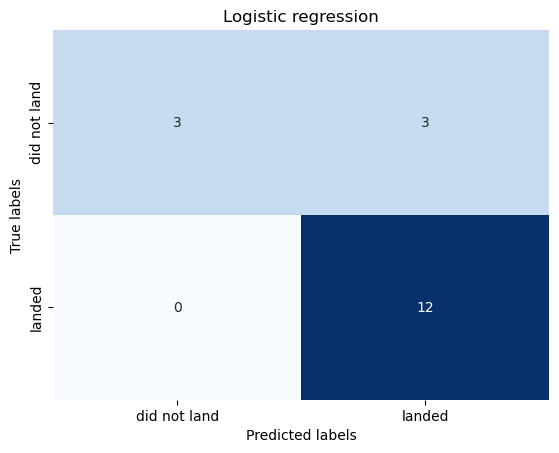

In [4]:
parameters = {"C": [0.01, 0.1, 1], "penalty": ["l2"], "solver": ["lbfgs"]}
logreg_cv = GridSearchCV(LogisticRegression(), parameters, cv=10).fit(X_train, Y_train)
print("Best parameters:", logreg_cv.best_params_)
print("Validation accuracy:", round(logreg_cv.best_score_, 4))
print("Test accuracy:", round(logreg_cv.score(X_test, Y_test), 4))
plot_confusion_matrix(Y_test, logreg_cv.predict(X_test), "Logistic regression")

## Support vector machine

Best parameters: {'C': np.float64(1.0), 'gamma': np.float64(0.03162277660168379), 'kernel': 'sigmoid'}
Validation accuracy: 0.8482
Test accuracy: 0.8333


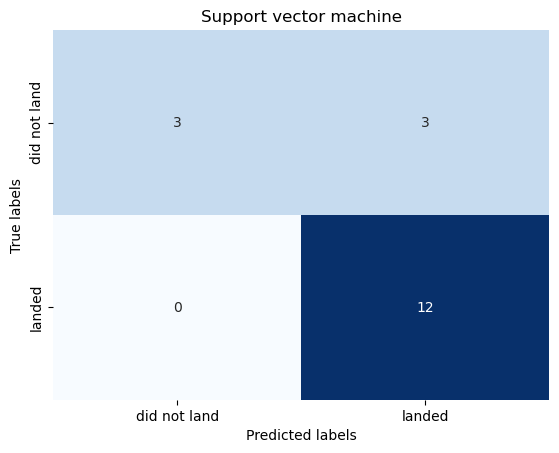

In [5]:
parameters = {"kernel": ("linear", "rbf", "poly", "sigmoid"),
              "C": np.logspace(-3, 3, 5),
              "gamma": np.logspace(-3, 3, 5)}
svm_cv = GridSearchCV(SVC(), parameters, cv=10).fit(X_train, Y_train)
print("Best parameters:", svm_cv.best_params_)
print("Validation accuracy:", round(svm_cv.best_score_, 4))
print("Test accuracy:", round(svm_cv.score(X_test, Y_test), 4))
plot_confusion_matrix(Y_test, svm_cv.predict(X_test), "Support vector machine")

## Decision tree

The course grid used `max_features='auto'`, which newer scikit-learn versions removed. For a classifier, `'auto'` meant `'sqrt'`, so the grid uses `'sqrt'` and `'log2'`.

Best parameters: {'criterion': 'gini', 'max_depth': 4, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'min_samples_split': 10, 'splitter': 'random'}
Validation accuracy: 0.8357
Test accuracy: 0.7778


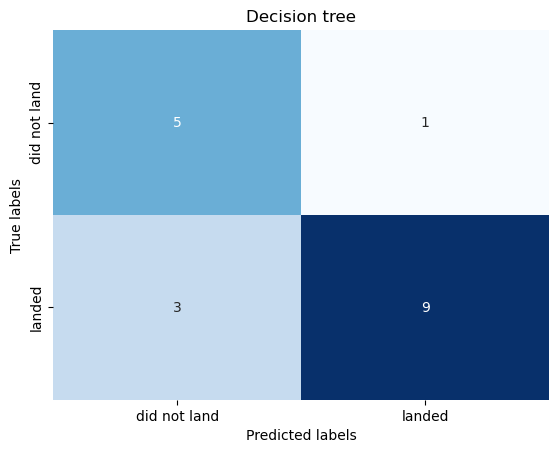

In [6]:
parameters = {"criterion": ["gini", "entropy"],
              "splitter": ["best", "random"],
              "max_depth": [2 * n for n in range(1, 10)],
              "max_features": ["sqrt", "log2"],
              "min_samples_leaf": [1, 2, 4],
              "min_samples_split": [2, 5, 10]}
tree_cv = GridSearchCV(DecisionTreeClassifier(random_state=1), parameters, cv=10).fit(X_train, Y_train)
print("Best parameters:", tree_cv.best_params_)
print("Validation accuracy:", round(tree_cv.best_score_, 4))
print("Test accuracy:", round(tree_cv.score(X_test, Y_test), 4))
plot_confusion_matrix(Y_test, tree_cv.predict(X_test), "Decision tree")

## K-nearest neighbors

Best parameters: {'algorithm': 'auto', 'n_neighbors': 10, 'p': 1}
Validation accuracy: 0.8482
Test accuracy: 0.8333


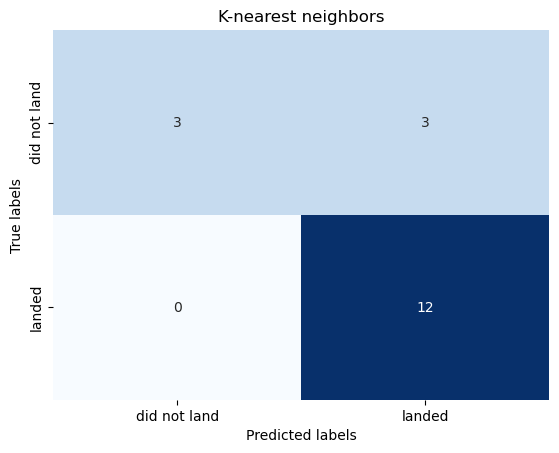

In [7]:
parameters = {"n_neighbors": list(range(1, 11)),
              "algorithm": ["auto", "ball_tree", "kd_tree", "brute"],
              "p": [1, 2]}
knn_cv = GridSearchCV(KNeighborsClassifier(), parameters, cv=10).fit(X_train, Y_train)
print("Best parameters:", knn_cv.best_params_)
print("Validation accuracy:", round(knn_cv.best_score_, 4))
print("Test accuracy:", round(knn_cv.score(X_test, Y_test), 4))
plot_confusion_matrix(Y_test, knn_cv.predict(X_test), "K-nearest neighbors")

## Which model performs best?

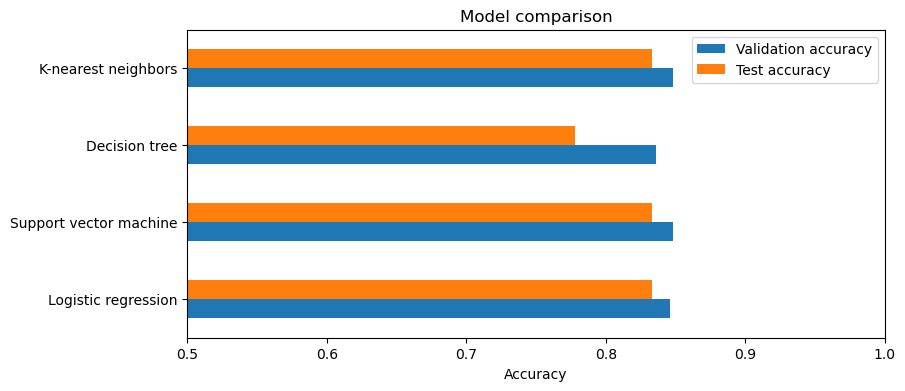

,Validation accuracy,Test accuracy
Support vector machine,0.8482,0.8333
K-nearest neighbors,0.8482,0.8333
Logistic regression,0.8464,0.8333
Decision tree,0.8357,0.7778


In [8]:
models = {"Logistic regression": logreg_cv, "Support vector machine": svm_cv,
          "Decision tree": tree_cv, "K-nearest neighbors": knn_cv}
results = pd.DataFrame({
    "Validation accuracy": {name: m.best_score_ for name, m in models.items()},
    "Test accuracy": {name: m.score(X_test, Y_test) for name, m in models.items()},
}).round(4)

results.plot(kind="barh", figsize=(9, 4), xlim=(0.5, 1))
plt.xlabel("Accuracy")
plt.title("Model comparison")
plt.show()
results.sort_values("Validation accuracy", ascending=False)